# 00 · Feasibility check

**Question:** Can a simple model predict *which hours of tomorrow will be cheap*, before the
prices are known?

Tomorrow's day-ahead prices are set in an auction at 12:00 and published at around 12:45.
Many decisions (bids for that auction, shift planning) are made earlier, so the project needs a
forecast that only uses what is known **before 12:00 on the day before**.

**Go criteria, fixed in advance.** Compared with the rule of thumb *"tomorrow's prices are the
same as today's"*, the model must

1. have an error (MAE) that is at least **10 % lower**, and
2. find the **4 cheapest hours** of a day **more often**.

Data: Bundesnetzagentur | SMARD.de, [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).

**Terms used in this notebook**

| term | meaning |
|---|---|
| day-ahead price | price of electricity for each hour of *tomorrow*, set in a daily auction |
| €/MWh | euros per megawatt-hour; 100 €/MWh = 10 ct/kWh (exchange price only, no grid fees or taxes) |
| residual load | electricity demand minus wind and solar, i.e. what coal, gas, storage and imports still have to cover |
| forecast | the grid operators' prediction of demand, wind and solar for tomorrow, published before the auction |
| MAE | *mean absolute error*: the average gap between forecast and real price, ignoring whether it was too high or too low |
| rule of thumb / baseline | a very simple prediction that any model must beat to be worth using |

Each output below is followed by a short **How to read this** note.

In [1]:
from pathlib import Path

import holidays
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from emi.smard import REGION, SERIES, SmardClient

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
TZ = "Europe/Berlin"
START = pd.Timestamp("2025-11-03", tz=TZ)  # one year plus one week (needed for a 7-day lag)
END = pd.Timestamp("2026-11-18", tz=TZ)  # exclusive

INK, MUTED, SURFACE = "#0b0b0b", "#898781", "#fcfcfb"
BLUE, ORANGE = "#2a78d6", "#eb6834"
plt.rcParams.update(
    {
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": MUTED,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e1",
        "font.size": 10,
        "figure.dpi": 110,
    }
)

## 1 · Data

Hourly SMARD data for Germany/Luxembourg: the day-ahead **price** and the grid operators'
**forecasts** for tomorrow (consumption, wind + solar, solar, and the *residual load* =
consumption minus wind and solar). Downloads are cached in `data/smard_cache/`.

**Output:** how many hours were loaded, the date range, and how many values are missing.

In [2]:
client = SmardClient(cache_dir=ROOT / "data" / "smard_cache")
keys = ["price", "fc_residual_load", "fc_load", "fc_wind_solar", "fc_solar"]
df = pd.DataFrame(
    {k: client.fetch_range(SERIES[k].filter_id, START, END, region=REGION) for k in keys}
)
df.index = df.index.tz_convert(TZ)
print(f"{len(df):,} hours, {df.index.min():%d %b %Y} to {df.index.max():%d %b %Y}")
print(f"missing values: {df.isna().sum().sum()}")

9,120 hours, 03 Nov 2025 to 17 Nov 2026
missing values: 0


**How to read this.** 9,120 hours = 380 days × 24 hours: one year plus one extra week
(the model looks one week back, so the first week only serves as history). No value is missing
in these five series, so no gaps need to be filled.

## 2 · Does the forecast say anything about the price?

Before building a model we check whether the forecasts and the price are related at all. If
not, no model could predict cheap hours from them.

**What the chart shows:** each blue dot is one hour of the year (about 9,100 dots).

* **x-axis:** the **forecast residual load** for that hour in GWh, i.e. how much electricity will
  still be needed from coal, gas, storage or imports after wind and solar. Left = lots of wind
  and solar, right = little. Below 0 means wind and solar are expected to produce *more* than
  the whole demand.
* **y-axis:** the actual day-ahead price of that hour.
* **orange line:** the typical price (*median*: half of the hours are cheaper, half more
  expensive) at each level of residual load. Unlike an average, it is not pulled around by a
  few extreme hours.

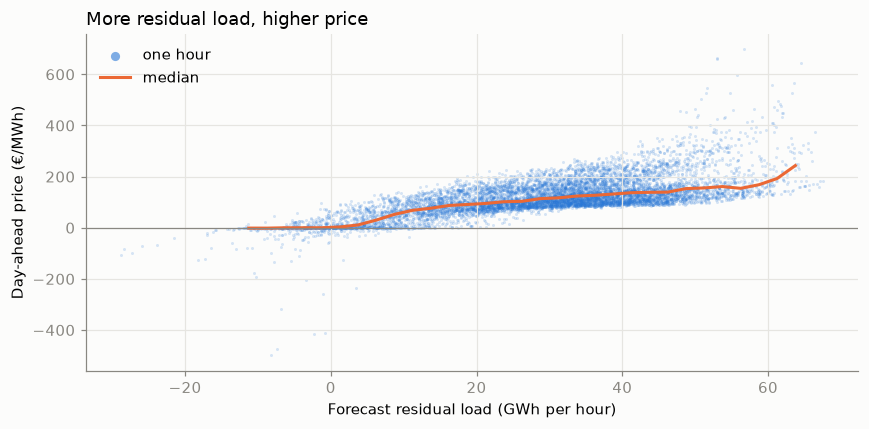

In [3]:
x = df.fc_residual_load / 1000  # MWh -> GWh
bins = np.arange(-30, 72.5, 2.5)
groups = df.price.groupby(pd.cut(x, bins), observed=True)
median = groups.median()[groups.size() >= 30]

fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(x, df.price, s=4, color=BLUE, alpha=0.18, linewidths=0, label="one hour")
ax.plot([iv.mid for iv in median.index], median, color=ORANGE, linewidth=2, label="median")
ax.axhline(0, color=MUTED, linewidth=0.8)
ax.set_xlabel("Forecast residual load (GWh per hour)")
ax.set_ylabel("Day-ahead price (€/MWh)")
ax.set_title("More residual load, higher price", loc="left")
legend = ax.legend(frameon=False, loc="upper left", markerscale=3)
legend.legend_handles[0].set_alpha(0.6)
fig.tight_layout()

**How to read this.** The cloud rises from left to right, and the orange line shows it clearly:

* around **0 GWh** or below, the price is typically about **0 €/MWh**; the dots far below zero
  (down to about −500 €/MWh) are hours with negative prices, when producers pay to get rid of
  their power,
* around **20 GWh** a typical hour costs about **95 €/MWh**, around **40 GWh** about **135 €/MWh**,
* above **60 GWh** it is typically around **200 €/MWh**, with single hours up to about 700 €/MWh.

So the forecast says a lot about the price, and it is available *before* the auction. That makes
it a good model input.

## 3 · Model vs. rule of thumb

Two ways to predict tomorrow's 24 prices:

* **Yesterday** (the rule of thumb): each hour costs the same as the same hour today.
* **Model:** a *linear regression*, using only information available before 12:00:
  * the forecasts for tomorrow (residual load, consumption, wind + solar, solar)
  * today's and last week's price for the same hour, today's average price
  * hour of the day, weekday, public holiday

**Linear regression** in one sentence: the model learns one weight per input from past data
(e.g. "+1 GWh residual load → about +x €/MWh") and adds them up to a price. *Ridge* is a variant
that keeps the weights small, which makes it more stable when inputs are similar to each other
(like the different forecasts).

**Fair test (walk-forward):** we replay the last 26 weeks one by one. For each week the model is
trained only on data *before* that week (*training*) and then predicts that week (*testing*).
So it never sees the answers in advance, just like in real use.

**Output:** the test period and its length.

In [4]:
# Model inputs (one row per hour)
X = df[["fc_residual_load", "fc_load", "fc_wind_solar", "fc_solar"]] / 1000
X = X.assign(fc_residual_load_sq=X.fc_residual_load**2 / 10)
X["price_lag24"] = df.price.shift(24)
X["price_lag168"] = df.price.shift(168)
daily_mean = df.price.groupby(df.index.date).mean()
X["prev_day_mean"] = pd.Series(df.index.date, index=df.index).map(daily_mean.shift(1)).to_numpy()
de_holidays = holidays.Germany(years=sorted({d.year for d in df.index}))
X["holiday"] = [d.date() in de_holidays for d in df.index]
X = X.join(pd.get_dummies(pd.Series(df.index.hour, index=df.index), prefix="hour"))
X = X.join(pd.get_dummies(pd.Series(df.index.day_of_week, index=df.index), prefix="dow"))
X, y = X.astype(float), df.price
usable = X.notna().all(axis=1)

# Walk-forward test: retrain every week on all earlier data
TEST_START = pd.Timestamp("2026-05-18", tz=TZ)
preds = []
for week_start in pd.date_range(TEST_START, END - pd.Timedelta(days=1), freq="7D"):
    train = usable & (df.index < week_start)
    test = usable & (df.index >= week_start) & (df.index < week_start + pd.Timedelta(days=7))
    model = make_pipeline(StandardScaler(), Ridge(alpha=1.0)).fit(X[train], y[train])
    preds.append(pd.Series(model.predict(X[test]), index=X.index[test]))

ev = pd.DataFrame({"actual": y, "yesterday": X.price_lag24, "model": pd.concat(preds)}).dropna()
print(f"test period: {ev.index.min():%d %b} to {ev.index.max():%d %b %Y} ({len(ev):,} hours)")

test period: 18 May to 17 Nov 2026 (4,416 hours)


**How to read this.** 4,416 hours = 184 days (18 May to 17 Nov 2026) were predicted, each by a
model that had never seen them. The table `ev` now holds, for every one of these hours, the
actual price and the two predictions. All results below are computed from it.

### Results

For load shifting the exact price matters less than **which hours** are cheapest. Imagine a
machine that needs 4 hours a day: each method picks the 4 hours it *thinks* are cheapest, and we
look at what those hours *actually* cost.

* **MAE:** average error per hour (€/MWh), lower is better
* **Top-4 hit rate:** how many of the truly cheapest 4 hours were picked (1.0 = all four)
* **Price paid:** average actual price of the 4 picked hours (€/MWh), lower is better

**Example for one day:** the truly cheapest hours are 11, 12, 13 and 14 o'clock. A method picks
12, 13, 14 and 15 o'clock. Three of four are right → hit rate 0.75. The table shows the average
over all 184 test days.

*Perfect knowledge* is the best possible plan, made with the real prices. Nobody can do better,
so it is the benchmark. The line above the table gives the average price of *all* hours: that is
roughly what the machine would pay without any planning.

In [5]:
def pick_cheapest(ev, method, k=4):
    rows = []
    for _, day in ev.groupby(ev.index.date):
        best = day.actual.nsmallest(k).index
        chosen = day[method].nsmallest(k).index
        rows.append({"hit": len(best.intersection(chosen)) / k, "paid": day.actual[chosen].mean()})
    return pd.DataFrame(rows).mean()


results = pd.DataFrame(
    {
        name: {
            "MAE (€/MWh)": (ev[method] - ev.actual).abs().mean(),
            "top-4 hit rate": pick_cheapest(ev, method).hit,
            "price paid (€/MWh)": pick_cheapest(ev, method).paid,
        }
        for name, method in [
            ("yesterday", "yesterday"),
            ("model", "model"),
            ("perfect knowledge", "actual"),
        ]
    }
).T
print(f"average price of all hours (no shifting): {ev.actual.mean():.1f} €/MWh")
results.round(2)

average price of all hours (no shifting): 139.5 €/MWh


,MAE (€/MWh),top-4 hit rate,price paid (€/MWh)
yesterday,36.29,0.76,67.81
model,28.56,0.84,63.35
perfect knowledge,0.00,1.00,61.78


**How to read this.** Read the table row by row:

* **yesterday:** off by 36 €/MWh per hour on average; it finds 0.76 × 4 ≈ 3 of the 4 cheapest
  hours, and the picked hours cost 67.8 €/MWh.
* **model:** off by only 28.6 €/MWh (about a fifth less); it finds 0.84 × 4 ≈ 3.4 of the 4
  cheapest hours, and the picked hours cost **63.4 €/MWh**.
* **perfect knowledge:** no error, all 4 hours right, 61.8 €/MWh. That is the lower limit.

Compared with the average price of 139.5 €/MWh, the model-based plan pays **less than half**,
and only about 1.6 €/MWh more than with perfect knowledge. In other words: almost all of the
possible savings come from shifting the load, and the model loses only a small part of them.

**The example week below** is the test week with the largest price swings (9–15 Nov 2026).
The chart has two parts that share the same time axis:

* **Top:** the prices. **Black** = actual price, **blue** = model, **orange dashed** =
  *yesterday*. The circled numbers mark the spots explained below the chart.
* **Bottom:** for each day, the 4 hours each method would pick for the machine. **Filled** bars
  are hits (the hour really is one of the 4 cheapest), **outlined** bars are misses. The black
  row (*perfect knowledge*) shows the truly cheapest hours, so a filled blue or orange bar sits
  exactly below a black one.

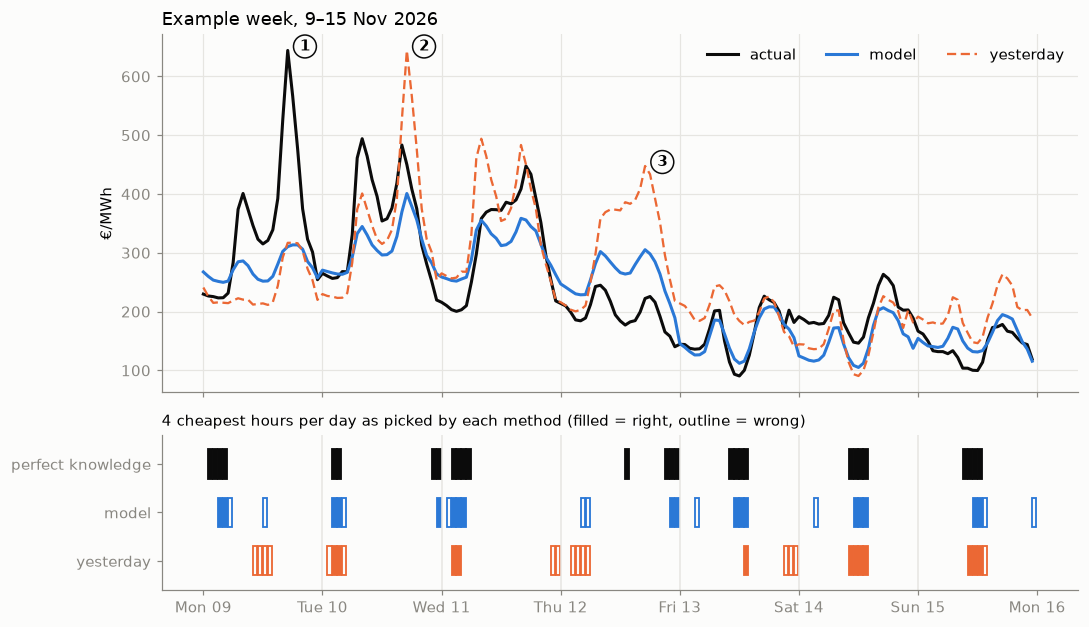

In [6]:
week = ev.loc["2026-11-09":"2026-11-15"]
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(10, 5.8), sharex=True, height_ratios=[3, 1.3])

# Top: prices
ax.plot(week.index, week.actual, color=INK, linewidth=2, label="actual")
ax.plot(week.index, week.model, color=BLUE, linewidth=2, label="model")
ax.plot(week.index, week.yesterday, color=ORANGE, linewidth=1.5, ls=(0, (4, 2)), label="yesterday")
ax.set_ylabel("€/MWh")
ax.set_title("Example week, 9–15 Nov 2026", loc="left")
ax.legend(frameon=False, ncols=3, loc="upper right")

# Number the three spots discussed in the text below the chart
for number, column, day in [
    ("1", "actual", "2026-11-09"),
    ("2", "yesterday", "2026-11-10"),
    ("3", "yesterday", "2026-11-12"),
]:
    t = week.loc[day, column].idxmax()
    ax.annotate(
        number,
        xy=(t, week.loc[t, column]),
        xytext=(8, 0),
        textcoords="offset points",
        fontweight="bold",
        bbox={"boxstyle": "circle,pad=0.25", "facecolor": SURFACE, "edgecolor": INK},
    )

# Bottom: the 4 hours each method picks per day.
# Filled = one of the truly 4 cheapest hours (a hit), outline only = a miss.
rows = [
    ("perfect knowledge", "actual", INK),
    ("model", "model", BLUE),
    ("yesterday", "yesterday", ORANGE),
]
for row, (_label, method, color) in enumerate(rows):
    y_row = len(rows) - 1 - row
    for _, day in week.groupby(week.index.date):
        best = day.actual.nsmallest(4).index
        for hour in day[method].nsmallest(4).index:
            ax2.bar(
                hour,
                0.6,
                width=pd.Timedelta(minutes=50),
                bottom=y_row - 0.3,
                align="edge",
                color=color if hour in best else SURFACE,
                edgecolor=color,
                linewidth=1.2,
            )
for midnight in pd.date_range("2026-11-10", periods=6, freq="D", tz=TZ):
    ax2.axvline(midnight, color="#e6e5e1", linewidth=1)
ax2.set_yticks(range(len(rows)), [label for label, _, _ in reversed(rows)])
ax2.set_ylim(-0.6, len(rows) - 0.4)
ax2.grid(False)
ax2.set_title(
    "4 cheapest hours per day as picked by each method (filled = right, outline = wrong)",
    loc="left",
    fontsize=10,
)
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%a %d", tz=TZ))
fig.tight_layout()

**How to read this.**

* **(1)** On Monday evening the price jumps to about 650 €/MWh.
* **(2)** *Yesterday* repeats this spike one day later, on Tuesday evening, when the real price
  was clearly lower. It is the black line **shifted by one day**.
* **(3)** The same on Thursday: *yesterday* repeats Wednesday's high prices, although the price
  had already dropped.

The model (blue) uses the wind, solar and demand forecasts for the *same* day, so it rises and
falls at the right times. It does not reach the highest peaks, though, and tends to be too low
(see caveats below).

**Bottom part:** the model gets 2 or 3 of the 4 cheapest hours right on every day of this week
(18 of 28 in total). *Yesterday* swings between 0 and 4 (12 of 28): on Monday and Thursday it
misses all four, because the cheap hours of the previous day were at a different time. On
Saturday it hits all four, because on both Friday and Saturday the cheapest hours were
exactly the same (10:00–14:00, midday solar).

## 4 · Decision

The next cell compares the results with the two go criteria from the top of the notebook.

**Output:** each criterion with the measured value and the threshold, then the decision.

In [7]:
mae_gain = 1 - results.loc["model", "MAE (€/MWh)"] / results.loc["yesterday", "MAE (€/MWh)"]
hit_gain = results.loc["model", "top-4 hit rate"] - results.loc["yesterday", "top-4 hit rate"]
print(f"1. MAE lower by {mae_gain:.0%}  (needed: at least 10 %)")
print(f"2. hit rate higher by {hit_gain:+.2f}  (needed: more than 0)")
print("Decision:", "GO" if mae_gain >= 0.10 and hit_gain > 0 else "NO-GO")

1. MAE lower by 21%  (needed: at least 10 %)
2. hit rate higher by +0.08  (needed: more than 0)
Decision: GO


**Go.** Even a simple model finds the cheap hours reliably. The project continues as planned.

**Caveats, handled in the next steps:**

* **Forecast timing:** SMARD doesn't record when a forecast was published. Whether tomorrow's
  forecasts are online before 12:00 has to be checked live.
* **Price level:** the model is on average about 20 €/MWh too low, because prices roughly
  doubled over the year (fuel and CO₂ costs, which SMARD doesn't contain). This hardly changes
  *which* hours are cheapest. A shorter training window helps; it will be chosen on day 5.
* **Small setup:** one year of data, no tuning. Good enough for a go/no-go, not a final
  result.